# 衰减加权月频成交量（ATTN）

**行为金融因子 —— 投资者注意力**

衰减加权月频成交量因子通过对过去 12 个月的成交量按月线性衰减加权求和得到，赋予近期成交量更高的权重：

$$
\text{ATTN}_t = \sum_{m=1}^{11} \frac{12 - m}{\sum_{k=1}^{11} k} \cdot VOL_{i, t-m}
$$

其中，分母为权重归一化常数：

$$
\sum_{k=1}^{11} k = \frac{11 \times 12}{2} = 66
$$

因此，因子可简化为：

$$
\text{ATTN}_t = \sum_{m=1}^{11} \frac{12 - m}{66} \cdot VOL_{i, t-m}
$$

各变量定义如下：

* $VOL_{i, t-m}$ 为股票 $i$ 在 $t-m$ 月的月频成交量（共取过去 11 个月，加上当月共覆盖 12 个月度窗口）；
* $m$ 为月份滞后阶数，从 1 到 11，取值越大，对应的成交量越早，权重越低；
* $\frac{12 - m}{66}$ 为线性衰减权重，权重随 $m$ 增大而递减（即近期权重高、远期权重低）。

## 因子说明

衰减加权月频成交量因子通过对股票历史成交量进行时间衰减加权得到，属于**极端交易量类因子**。

异常成交量是投资者注意力的常用代理指标之一。因子取值越高，表明该股票近期成交量持续活跃，投资者的关注度也就越高。

然而，投资者的注意力是有限的，他们更倾向于交易那些引起自己注意的股票。通常情况下，关注度较高的股票会伴随更多的买入行为。但在 A 股市场中，由于**做多与做空机制不对称**，投资者非理性买入的倾向强于非理性卖出，导致高关注度股票因净买入力量而出现短期价格溢价，这种过度反应往往会在未来引发价格反转。

数据：日度成交量

代码与公式 $m=1,\dots,11$ 是一致的，且没有未来函数：当月 $ATTＮ$ 只使用上月到前第 11 月的完整月度成交量，月初更新、月内不变。🚨但说明文字应修正为“过去 11 个完整月份”，而不是“加上当月共覆盖 12 个月”。当前实现不使用当月成交量。还有一个金融含义提醒：$ATTN$ 是“近期成交量水平”的衰减加权均值，不是相对自身历史的异常成交量；高值也会反映大市值、高流动性股票。其作为注意力因子使用时，建议后续做行业、市值或流动性中性化。

In [1]:
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel

def calculate_attn_daily(
    start_date,
    end_date,
    completed_months=12,
    candidate_ids=None,
    batch_size=500,
):
    """
    计算衰减加权月频成交量（ATTN），并映射为日频因子。

    对当前输出月 M，使用此前 12 个已完成月：
    M-1、M-2、...、M-12。

    权重为：
    12/78、11/78、...、1/78。

    因子在每月第一个交易日更新，月内保持不变。
    """
    if completed_months != 12:
        raise ValueError("当前版本严格对应 12 个月线性衰减，completed_months 必须为 12。")

    # 12 个完整月历史，加上数据冗余。
    required_lookback = 400

    target_dates, volume_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=required_lookback,
    )

    candidate_ids = _get_ids(candidate_ids)
    factor_parts = []

    # 12 + 11 + ... + 1 = 78
    weight_denominator = completed_months * (completed_months + 1) / 2.0

    for start in range(0, len(candidate_ids), batch_size):
        batch = candidate_ids[start:start + batch_size]

        _, volume = _get_batch_close_volume(batch, volume_dates)

        if volume is None:
            continue

        month_index = volume.index.to_period("M")

        monthly_volume = volume.groupby(month_index).sum()

        monthly_trade_days = (
            volume.gt(0)
            .groupby(month_index)
            .sum()
        )

        monthly_attn = pd.DataFrame(
            0.0,
            index=monthly_volume.index,
            columns=batch,
        )

        valid_history = pd.DataFrame(
            True,
            index=monthly_volume.index,
            columns=batch,
        )

        # 输出月 M 使用 M-1 至 M-12 的完整月数据。
        for lag in range(1, completed_months + 1):
            weight = (
                completed_months + 1 - lag
            ) / weight_denominator

            monthly_attn += (
                weight * monthly_volume.shift(lag)
            )

            valid_history &= monthly_trade_days.shift(lag).gt(0)

        monthly_attn = monthly_attn.where(valid_history)

        # 映射到日频：每月首个交易日开始使用最新已完成月的数据。
        daily_attn = monthly_attn.reindex(month_index)
        daily_attn.index = volume.index

        # 仅在股票当日实际交易时保留因子。
        daily_attn = daily_attn.where(volume.gt(0))

        factor_wide = daily_attn.reindex(target_dates)

        factor_parts.append(
            _stack_factor(factor_wide, "ATTN")
        )

    if not factor_parts:
        return pd.DataFrame(columns=["ATTN"])

    return pd.concat(factor_parts).sort_index()

In [2]:
attn_panel = calculate_attn_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
)

attn_panel.head()

ATTN
date       order_book_id              
2020-01-02 000001.XSHE    2.027107e+09
           000002.XSHE    1.145690e+09
           000004.XSHE    2.245369e+07
           000005.XSHE    2.909695e+08
           000006.XSHE    2.075362e+08

,数值,判断
指标,,
目标交易日数,1.455000e+03,
有至少一个因子值的交易日数,1.455000e+03,应接近目标交易日数
完全无输出交易日数,0.000000e+00,应为 0
日频有效观测数,6.440491e+06,
月频去重后观测数,3.191220e+05,同一股票同月应只保留一个 ATTＮ 值
覆盖股票数,5.289000e+03,
重复 date-stock,0.000000e+00,应为 0
显式缺失值,0.000000e+00,最终 stack 后通常应为 0
无穷值（inf/-inf）,0.000000e+00,应为 0



最近 6 个月的月频横截面统计（单位：原始成交量）


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99
month,,,,,,,,,,
2025-07,5053,4.596749e+08,7.467485e+08,5.844444e+06,2.388132e+08,1.342904e+10,2.082780e+07,3.820150e+07,1.510644e+09,3.202602e+09
2025-08,5060,4.790086e+08,7.698717e+08,6.561291e+06,2.492635e+08,1.372551e+10,2.216472e+07,4.038480e+07,1.600080e+09,3.309787e+09
2025-09,5067,5.005706e+08,8.063129e+08,8.201596e+06,2.606989e+08,1.651012e+10,2.435443e+07,4.420080e+07,1.636952e+09,3.305592e+09
2025-10,5074,5.217529e+08,8.651389e+08,9.075120e+06,2.692003e+08,1.749966e+10,2.625549e+07,4.571021e+07,1.721758e+09,3.610692e+09
2025-11,5080,5.093710e+08,8.550629e+08,9.350537e+06,2.606722e+08,1.965386e+10,2.515435e+07,4.397462e+07,1.696895e+09,3.413187e+09
2025-12,5087,5.080089e+08,8.446940e+08,1.078523e+07,2.599424e+08,1.973177e+10,2.469590e+07,4.263327e+07,1.711439e+09,3.538544e+09



ATTN 最高的 20 条月度观测：


,month,order_book_id,ATTN,ATTN_亿股
1578666,2021-10,600010.XSHG,2.723373e+10,272.337282
1732511,2021-12,600010.XSHG,2.675481e+10,267.548097
1827058,2022-01,600010.XSHG,2.663973e+10,266.397267
1643233,2021-11,600010.XSHG,2.642234e+10,264.223354
1905768,2022-02,600010.XSHG,2.475467e+10,247.546697
1498501,2021-09,600010.XSHG,2.397836e+10,239.783606
1972549,2022-03,600010.XSHG,2.254820e+10,225.481985
2069418,2022-04,600010.XSHG,2.049466e+10,204.946635
4014308,2024-01,000656.XSHE,2.037588e+10,203.758778
1411688,2021-08,600010.XSHG,2.027317e+10,202.731664


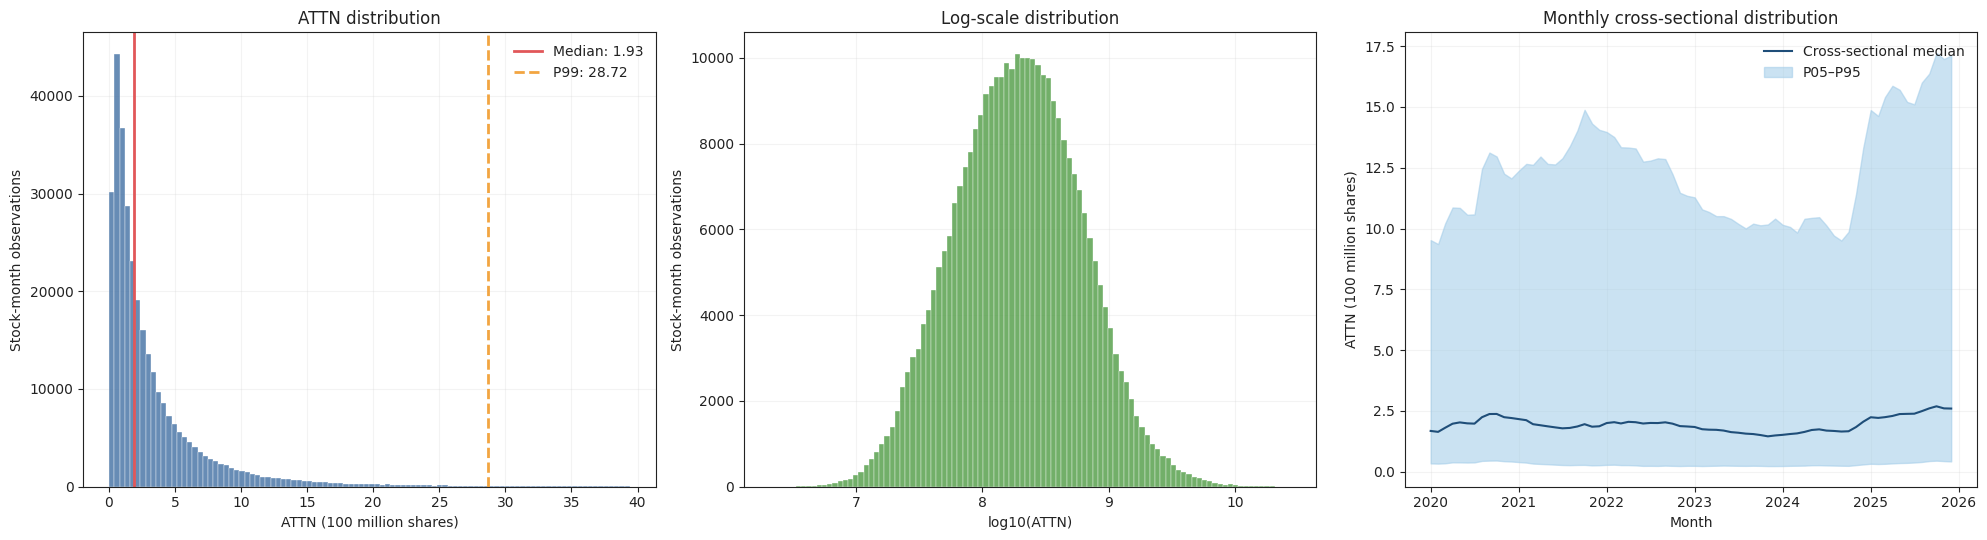

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from rqdatac import all_instruments, get_trading_dates

FACTOR_NAME = "ATTN"
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"
REQUIRED_MONTHS = 12

panel = attn_panel.copy()

if not isinstance(panel.index, pd.MultiIndex):
    raise ValueError("attn_panel 应为 date、order_book_id 两层 MultiIndex。")

if FACTOR_NAME not in panel.columns:
    raise ValueError("未找到因子列：{}".format(FACTOR_NAME))

check_data = pd.DataFrame({
    "date": pd.to_datetime(panel.index.get_level_values("date")),
    "order_book_id": panel.index.get_level_values("order_book_id"),
    FACTOR_NAME: pd.to_numeric(panel[FACTOR_NAME], errors="coerce").values,
})

expected_dates = pd.DatetimeIndex(
    pd.to_datetime(
        get_trading_dates(
            start_date=START_DATE,
            end_date=END_DATE,
        )
    )
)

raw_value = check_data[FACTOR_NAME]
is_finite = pd.Series(
    np.isfinite(raw_value.values),
    index=check_data.index,
)
is_valid = is_finite & raw_value.gt(0)

valid = check_data.loc[is_valid].copy()
valid["month"] = valid["date"].dt.to_period("M")

# ---------- 每日覆盖 ----------
daily_count = (
    valid.groupby("date")["order_book_id"]
    .nunique()
    .reindex(expected_dates)
    .fillna(0)
)
daily_count.index.name = "date"

daily_year = pd.Series(daily_count.index.year, index=daily_count.index)
daily_year_max = daily_count.groupby(daily_year).transform("max")
daily_relative_coverage = (
    daily_count / daily_year_max.replace(0, np.nan)
)

# ---------- 去除月内重复后的月频因子 ----------
monthly_factor = (
    valid.sort_values("date")
    .drop_duplicates(["order_book_id", "month"], keep="first")
    .copy()
)

monthly_cross = monthly_factor.groupby("month")[FACTOR_NAME].agg(
    ["count", "mean", "std", "min", "median", "max"]
)
monthly_cross.columns = [
    "因子股票数", "均值", "标准差",
    "最小值", "中位数", "最大值",
]
monthly_cross["P01"] = monthly_factor.groupby("month")[FACTOR_NAME].quantile(0.01)
monthly_cross["P05"] = monthly_factor.groupby("month")[FACTOR_NAME].quantile(0.05)
monthly_cross["P95"] = monthly_factor.groupby("month")[FACTOR_NAME].quantile(0.95)
monthly_cross["P99"] = monthly_factor.groupby("month")[FACTOR_NAME].quantile(0.99)

# ---------- 月内是否保持常数 ----------
within_month_unique = (
    valid.groupby(["order_book_id", "month"])[FACTOR_NAME]
    .nunique()
)
intra_month_changed = int((within_month_unique > 1).sum())

# ---------- 是否过早产生因子 ----------
first_factor_date = valid.groupby("order_book_id")["date"].min()

instruments_df = (
    all_instruments("CS")
    .drop_duplicates("order_book_id")
    .set_index("order_book_id")
)

listed_dates = pd.to_datetime(
    instruments_df["listed_date"].reindex(first_factor_date.index),
    errors="coerce",
)

listing_month = listed_dates.dt.to_period("M")
first_factor_month = first_factor_date.dt.to_period("M")

month_gap = (
    (first_factor_month.dt.year - listing_month.dt.year) * 12
    + (first_factor_month.dt.month - listing_month.dt.month)
)

early_factor_stocks = month_gap[
    month_gap < REQUIRED_MONTHS
].sort_values()

# ---------- 单股票覆盖 ----------
stock_days = valid.groupby("order_book_id").size()
stock_months = monthly_factor.groupby("order_book_id").size()

# ATTＮ单位为“股”；以下按亿股展示，便于阅读。
attn_100m = monthly_factor[FACTOR_NAME] / 1e8

summary = pd.DataFrame([
    ["目标交易日数", len(expected_dates), ""],
    ["有至少一个因子值的交易日数", int((daily_count > 0).sum()),
     "应接近目标交易日数"],
    ["完全无输出交易日数", int((daily_count == 0).sum()),
     "应为 0"],
    ["日频有效观测数", len(valid), ""],
    ["月频去重后观测数", len(monthly_factor),
     "同一股票同月应只保留一个 ATTＮ 值"],
    ["覆盖股票数", valid["order_book_id"].nunique(), ""],
    ["重复 date-stock", int(check_data.duplicated(["date", "order_book_id"]).sum()),
     "应为 0"],
    ["显式缺失值", int(raw_value.isna().sum()),
     "最终 stack 后通常应为 0"],
    ["无穷值（inf/-inf）", int(np.isinf(raw_value.values).sum()),
     "应为 0"],
    ["负值", int((raw_value < 0).sum()),
     "应为 0"],
    ["零值", int((raw_value == 0).sum()),
     "应为 0"],
    ["每日因子股票数均值", daily_count.mean(), ""],
    ["相对覆盖率 P05", daily_relative_coverage.quantile(0.05),
     "建议大于 0.80"],
    ["每月因子股票数 P05", monthly_cross["因子股票数"].quantile(0.05),
     "检查低覆盖月份"],
    ["单股有效交易日数 P05", stock_days.quantile(0.05), ""],
    ["单股有效月份数 P05", stock_months.quantile(0.05), ""],
    ["上市不足 12 个月即出现因子的股票数", len(early_factor_stocks),
     "应为 0"],
    ["月内发生因子变化的 stock-month 数", intra_month_changed,
     "应为 0：当月应保持不变"],
    ["ATTN 均值（亿股）", attn_100m.mean(), ""],
    ["ATTN 标准差（亿股）", attn_100m.std(), ""],
    ["ATTN 最小值（亿股）", attn_100m.min(),
     "应大于 0"],
    ["ATTN P01（亿股）", attn_100m.quantile(0.01), ""],
    ["ATTN 中位数（亿股）", attn_100m.median(), ""],
    ["ATTN P99（亿股）", attn_100m.quantile(0.99),
     "原始成交量因子通常明显右偏"],
    ["ATTN 最大值（亿股）", attn_100m.max(),
     "优先检查大市值股、股本变化或重大事件"],
], columns=["指标", "数值", "判断"])

display(summary.set_index("指标"))

print("\n最近 6 个月的月频横截面统计（单位：原始成交量）")
display(monthly_cross.tail(6))

print("\nATTN 最高的 20 条月度观测：")
top20 = monthly_factor.sort_values(
    FACTOR_NAME,
    ascending=False,
).head(20).copy()

top20["ATTN_亿股"] = top20[FACTOR_NAME] / 1e8
display(top20[["month", "order_book_id", FACTOR_NAME, "ATTN_亿股"]])

if len(early_factor_stocks) > 0:
    print("\n上市不足 12 个月即产生因子的股票：")
    display(early_factor_stocks.head(20).to_frame("上市至首次因子值的月数"))

# ---------- 白底分布图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
    "axes.unicode_minus": False,
})

plot_upper = attn_100m.quantile(0.995)
plot_values = attn_100m[attn_100m <= plot_upper]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# 原始量级分布，截断至 P99.5 便于观察主体
axes[0].hist(
    plot_values,
    bins=100,
    color="#4C78A8",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[0].axvline(
    attn_100m.median(),
    color="#E15759",
    linewidth=2,
    label="Median: {:.2f}".format(attn_100m.median()),
)
axes[0].axvline(
    attn_100m.quantile(0.99),
    color="#F2A541",
    linewidth=2,
    linestyle="--",
    label="P99: {:.2f}".format(attn_100m.quantile(0.99)),
)
axes[0].set_title("ATTN distribution")
axes[0].set_xlabel("ATTN (100 million shares)")
axes[0].set_ylabel("Stock-month observations")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

# 对数分布完整保留右尾
axes[1].hist(
    np.log10(monthly_factor[FACTOR_NAME]),
    bins=100,
    color="#59A14F",
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3,
)
axes[1].set_title("Log-scale distribution")
axes[1].set_xlabel("log10(ATTN)")
axes[1].set_ylabel("Stock-month observations")
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

# 月度横截面分布变化
plot_monthly = monthly_cross.copy()
plot_monthly.index = plot_monthly.index.to_timestamp()

axes[2].fill_between(
    plot_monthly.index,
    (plot_monthly["P05"] / 1e8).values,
    (plot_monthly["P95"] / 1e8).values,
    color="#A0CBE8",
    alpha=0.55,
    label="P05–P95",
)
axes[2].plot(
    plot_monthly.index,
    (plot_monthly["中位数"] / 1e8).values,
    color="#1F4E79",
    linewidth=1.5,
    label="Cross-sectional median",
)
axes[2].set_title("Monthly cross-sectional distribution")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("ATTN (100 million shares)")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[2].legend(frameon=False)
axes[2].grid(alpha=0.25)
axes[2].set_axisbelow(True)

plt.tight_layout()
plt.show()

- 1,455 个交易日均有输出，无重复、缺失、无穷值、负值或零值；
- 月内发生因子变化的 stock-month 数为 0，证明因子确实只在月初更新，未误用当月未完成成交量；
- 日频有效观测 644 万，月频去重后 31.9 万，数量关系合理；
- 月度覆盖 P05 为 3,584 只股票，覆盖稳定；
- 分布右偏合理：中位数为 1.93 亿股，P99 为 28.72 亿股，均值高于中位数是原始成交量因子的正常特征；
- 2025 年后半年中位数由约 2.39 亿股 升至 2.60 亿股，反映整体市场成交活跃度上升，变化平稳。

最高值集中于 600010.XSHG、000725.XSHE、000656.XSHE，这类大盘高流动性股票的历史月成交量达到百亿股级别是可以解释的，并不像此前 ABNVOLD 的数万倍问题那样属于分母失真。不过 ATTＮ 的核心风险不是数据错误，而是经济含义：它是“近期成交量水平”，天然会偏向大市值、高流动性股票。因此高 ATTＮ 不必然表示该股票的关注度相对自身历史异常升高。

In [4]:
# 行：交易日；列：order_book_id；值：ABNRETD
attn_panel_df = (
    attn_panel["ATTN"]
    .unstack("order_book_id")
    .sort_index()
)

attn_panel_df.index = pd.to_datetime(attn_panel_df.index)
attn_panel_df.columns.name = "order_book_id"

attn_panel_df

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,688787.XSHG,688788.XSHG,688789.XSHG,688793.XSHG,688798.XSHG,688799.XSHG,688800.XSHG,688819.XSHG,688981.XSHG,689009.XSHG
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,2.027107e+09,1.145690e+09,2.245369e+07,2.909695e+08,2.075362e+08,1.813919e+08,5.650862e+08,7.032874e+08,5.785493e+07,8.346677e+07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,2.027107e+09,1.145690e+09,2.245369e+07,2.909695e+08,2.075362e+08,1.813919e+08,5.650862e+08,7.032874e+08,5.785493e+07,8.346677e+07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,2.027107e+09,1.145690e+09,2.245369e+07,2.909695e+08,2.075362e+08,1.813919e+08,5.650862e+08,7.032874e+08,5.785493e+07,8.346677e+07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,2.027107e+09,1.145690e+09,2.245369e+07,2.909695e+08,2.075362e+08,1.813919e+08,5.650862e+08,7.032874e+08,5.785493e+07,8.346677e+07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,2.027107e+09,1.145690e+09,2.245369e+07,2.909695e+08,2.075362e+08,1.813919e+08,5.650862e+08,7.032874e+08,5.785493e+07,8.346677e+07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,2.328013e+09,2.740637e+09,1.453973e+08,NaN,1.035714e+09,1.833763e+08,1.621870e+09,8.065282e+08,8.193202e+08,2.351640e+08,...,5.635089e+07,1.306629e+08,3.576391e+07,3.712746e+07,71515573.0,9.668160e+07,3.339216e+08,8.564514e+07,1.168241e+09,2.293138e+08
2025-12-26,2.328013e+09,2.740637e+09,1.453973e+08,NaN,1.035714e+09,1.833763e+08,1.621870e+09,8.065282e+08,8.193202e+08,2.351640e+08,...,5.635089e+07,1.306629e+08,3.576391e+07,3.712746e+07,71515573.0,9.668160e+07,3.339216e+08,8.564514e+07,1.168241e+09,2.293138e+08
2025-12-29,2.328013e+09,2.740637e+09,1.453973e+08,NaN,1.035714e+09,1.833763e+08,1.621870e+09,8.065282e+08,8.193202e+08,2.351640e+08,...,5.635089e+07,1.306629e+08,3.576391e+07,3.712746e+07,71515573.0,9.668160e+07,3.339216e+08,8.564514e+07,1.168241e+09,2.293138e+08


In [5]:
from rqfactor.notebook import factor_analysis

result_attn = factor_analysis(
    f=attn_panel_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_attn.show()

Loading BokehJS ...

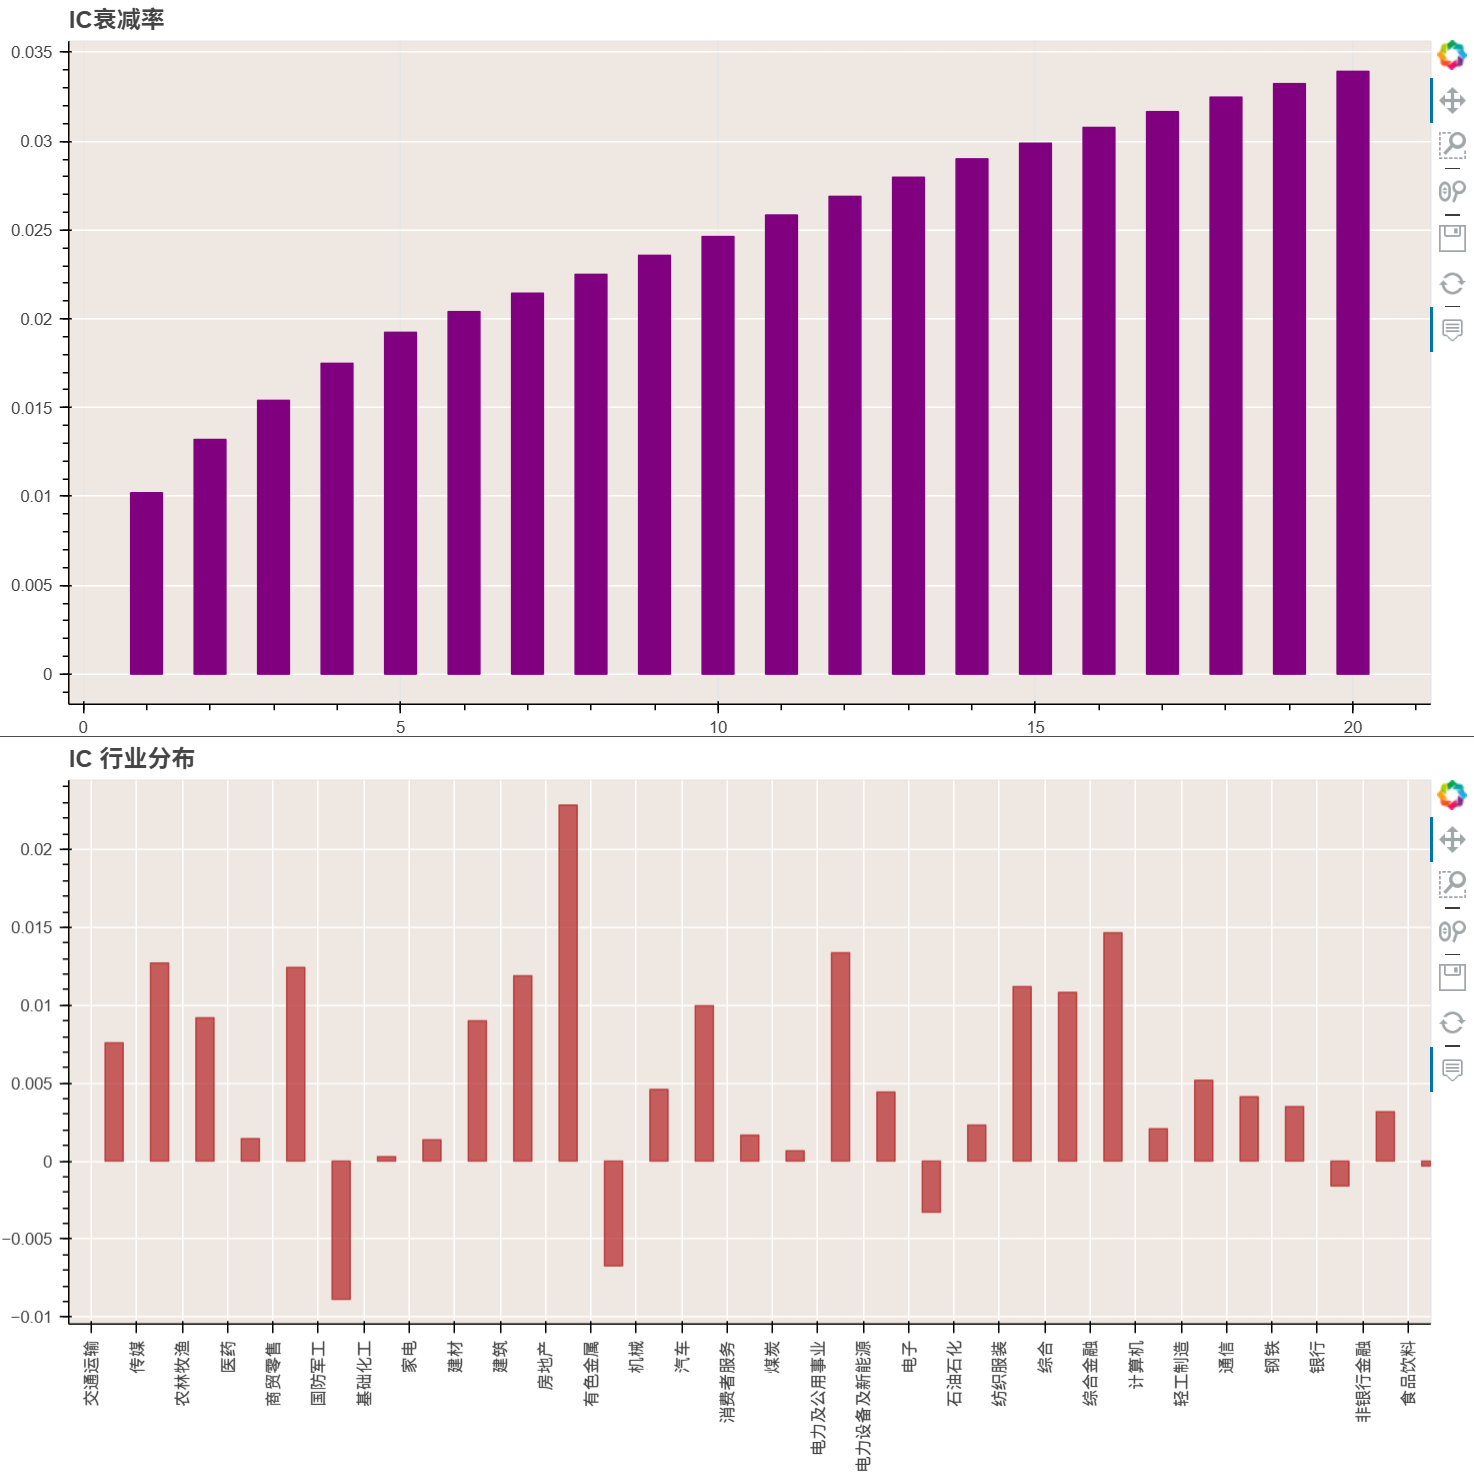

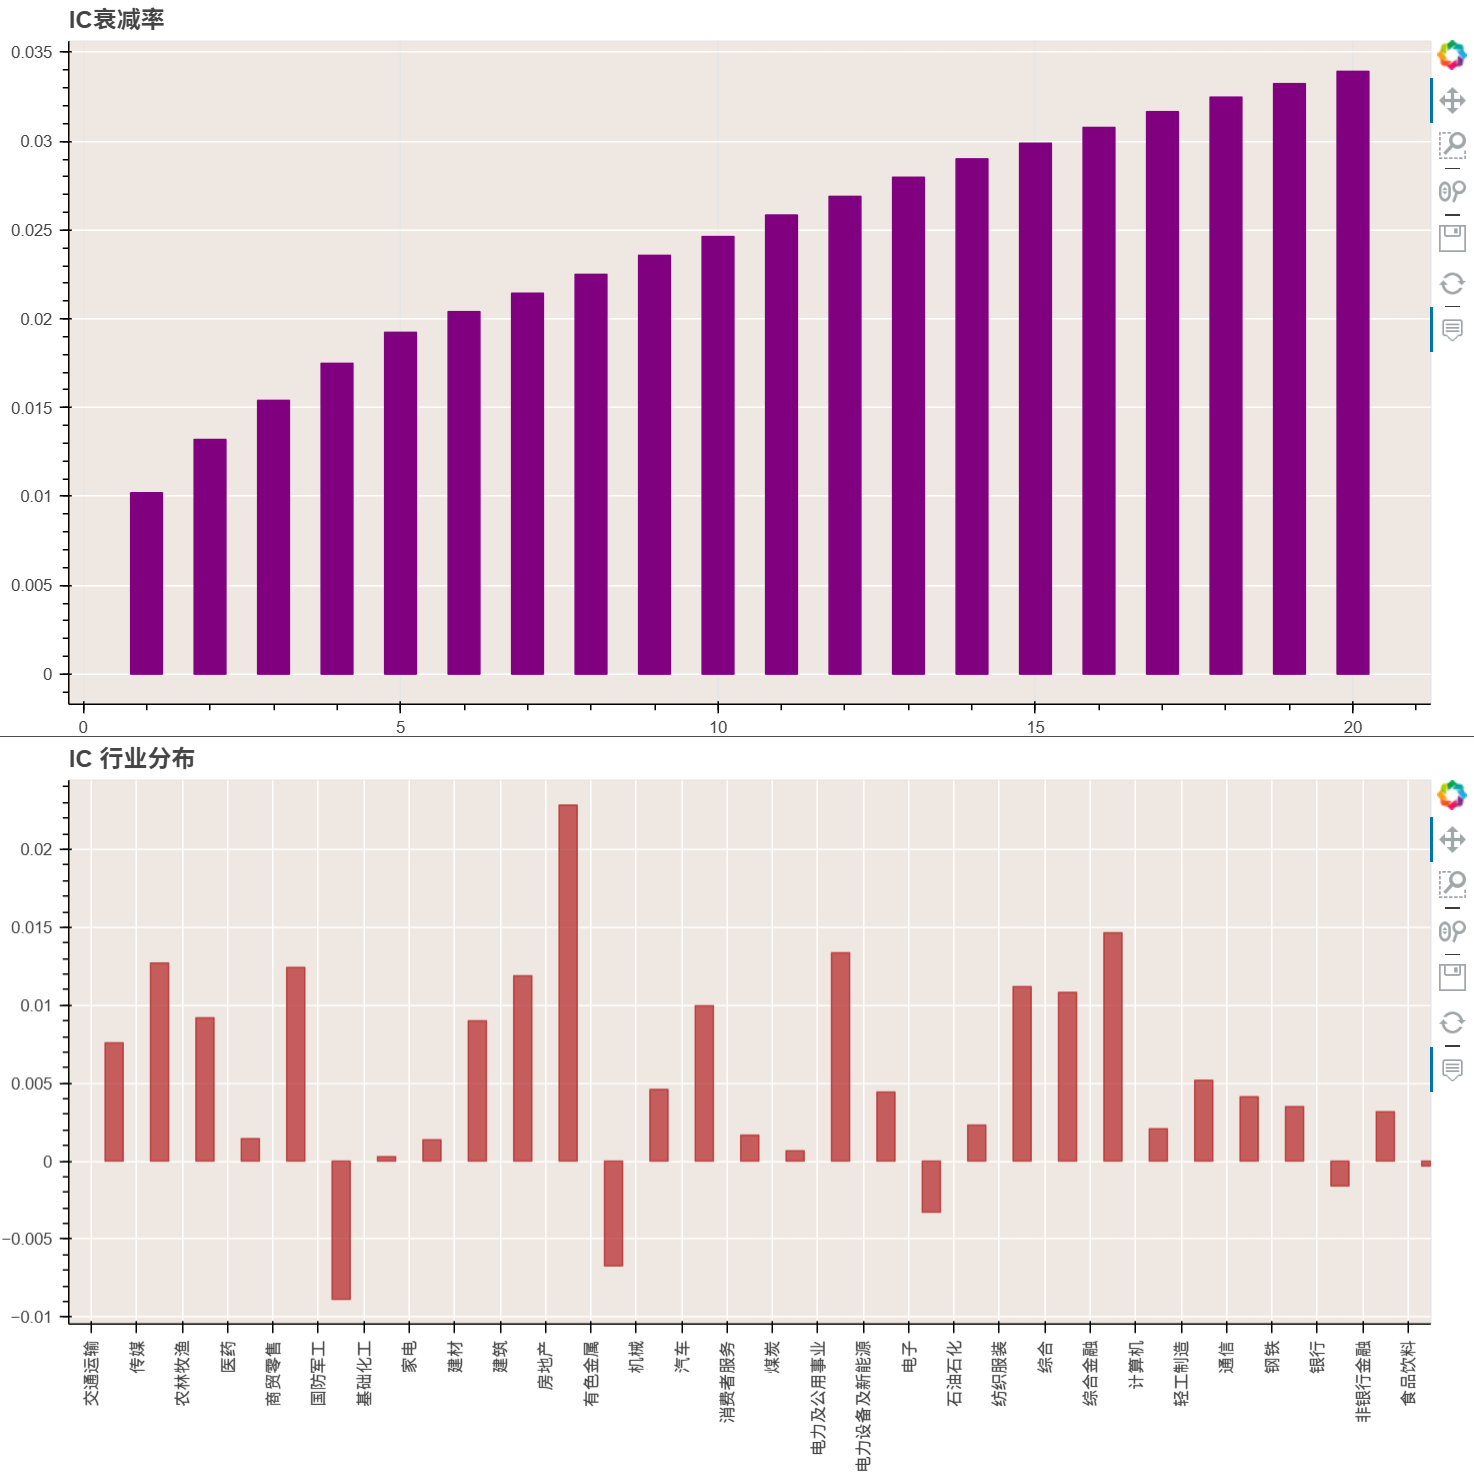

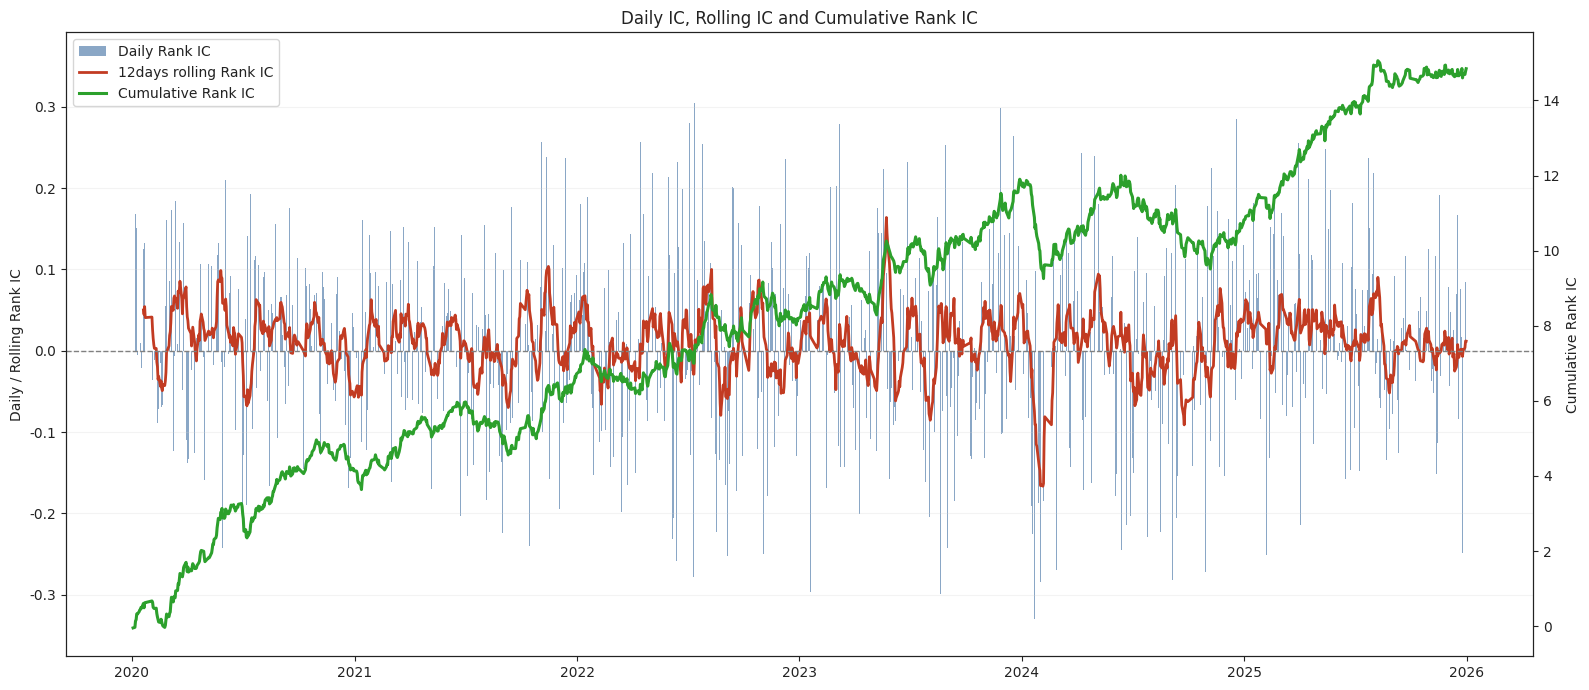

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_attn.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()